In [1]:
import numpy
import pandas
import seaborn

from matplotlib import pyplot

from fitting import TIMESERIES_TABLE_PATH
from realistic import PARAMS

In [2]:
pyplot.rcParams["figure.figsize"] = [12.8, 9.6]

In [3]:
def err(obs, model):
    scale = numpy.abs(obs)
    scale[scale == 0] = 1
    return numpy.abs(obs - model) / scale

In [4]:
params = (
    ('a', 'fitted_a'),
    ('e', 'fitted_e'),
    ('periapsis_phase', 'fitted_periapsis_phase'),
    ('Macc', 'fitted_Macc'),
    ('Porb', 'fitted_porb')
)

In [5]:
results = pandas.read_parquet(TIMESERIES_TABLE_PATH)
results = results[results['Porb'] <= PARAMS['campaign_baselines'][-1]]
# results['err'] = numpy.mean(numpy.array([err(results[o], results[m]) for o, m in params]), axis=0)
len(results)

1000

In [6]:
results['close'] = (
    numpy.isclose(results['a'], results['fitted_a'], rtol=5e-1)
    & numpy.isclose(results['Macc'], results['fitted_Macc'], rtol=1)
    & numpy.isclose(results['Porb'], results['fitted_porb'], rtol=5e-1)
)
results['close'].value_counts()

close
False    743
True     257
Name: count, dtype: int64

In [7]:
results[['a', 'fitted_a', 'Macc', 'fitted_Macc', 'Porb', 'fitted_porb', 'close']]

,a,fitted_a,Macc,fitted_Macc,Porb,fitted_porb,close
0,3.95,3.952017,10.357143,10.373538,850.862779,850.900786,True
1,2.20,1.457134,9.285714,3.986056,371.633812,287.719312,False
2,3.25,3.229277,20.000000,19.597284,466.996710,467.037174,True
3,0.45,49.071626,18.928571,19.691194,24.698985,27602.684440,False
4,0.10,34.733018,8.214286,10.831653,3.805113,21736.494010,False
...,...,...,...,...,...,...,...
995,2.55,0.071688,14.642857,0.284675,376.054386,6.185480,False
996,4.30,21.189129,9.285714,12.372358,1015.509246,9742.358324,False
997,0.10,31.075192,12.500000,35.024735,3.143631,10541.896981,False
998,2.90,7.008040,8.214286,14.092995,594.243700,1744.237345,False


In [8]:
# for o, m in params:
#     results[f'{o} - {m}'] = numpy.abs(results[o] - results[m])
#     results[f'({o} - {m})/{o}'] = numpy.abs((results[o] - results[m])/results[o])

In [9]:
# seaborn.displot(data=results, x='a - fitted_a', y='Porb')

In [10]:
# seaborn.displot(data=results, x='(a - fitted_a)/a', y='Porb')
# # pyplot.xscale('log')

In [11]:
# seaborn.displot(data=results, x='Macc - fitted_Macc', y='cadence')

In [12]:
# seaborn.displot(data=results, x='(Macc - fitted_Macc)/Macc', y='cadence')
# pyplot.xscale('log')

In [13]:
# seaborn.displot(data=results, x='(Macc - fitted_Macc)/Macc', y='RV accuracy')
# pyplot.yscale('log')

In [14]:
# seaborn.scatterplot(data=results, x='(Macc - fitted_Macc)/Macc', y='RV accuracy', hue='Macc')
# pyplot.yscale('log')

In [15]:
# seaborn.displot(data=results, x='(Macc - fitted_Macc)/Macc', y='baseline')
# # pyplot.xscale('log')

In [16]:
# a = seaborn.swarmplot(data=results, x='baseline', y='Macc', hue='(Macc - fitted_Macc)/Macc')
# seaborn.move_legend(a, "upper left", bbox_to_anchor=(1, 1))

In [17]:
# a = seaborn.swarmplot(data=results, x='baseline', y='a', hue='(a - fitted_a)/a')
# seaborn.move_legend(a, "upper left", bbox_to_anchor=(1, 1))

In [18]:
# a = seaborn.swarmplot(data=results, x='baseline', y='Porb', hue='(Porb - fitted_porb)/Porb')
# seaborn.move_legend(a, "upper left", bbox_to_anchor=(1, 1))

In [19]:
# a = seaborn.swarmplot(data=results, x='RV accuracy', y='Porb', hue='(Porb - fitted_porb)/Porb')
# seaborn.move_legend(a, "upper left", bbox_to_anchor=(1, 1))

In [20]:
# a = seaborn.swarmplot(data=results, x='RV accuracy', y='a', hue='(a - fitted_a)/a')
# seaborn.move_legend(a, "upper left", bbox_to_anchor=(1, 1))

In [21]:
# a = seaborn.swarmplot(data=results, x='RV accuracy', y='Macc', hue='(Macc - fitted_Macc)/Macc')
# seaborn.move_legend(a, "upper left", bbox_to_anchor=(1, 1))

/Users/adam/.local/share/virtualenvs/src-VJqicAka/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 6.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/Users/adam/.local/share/virtualenvs/src-VJqicAka/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 7.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/Users/adam/.local/share/virtualenvs/src-VJqicAka/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 14.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/Users/adam/.local/share/virtualenvs/src-VJqicAka/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 10.3% of the points cannot be placed; you may want to decrease the size of the markers or use strippl

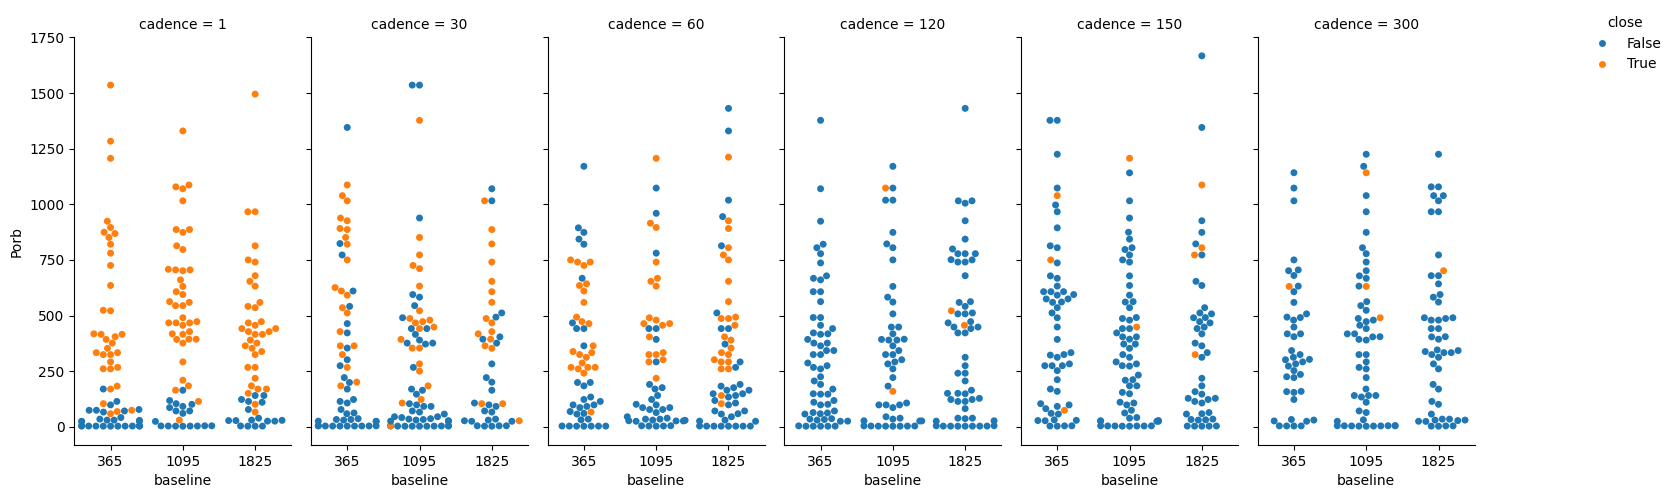

In [22]:
# a = seaborn.swarmplot(data=results, x='baseline', y='Porb', hue='close', col='cadence')
a = seaborn.catplot(
    data=results, kind="swarm",
    x='baseline', y='Porb', hue='close', col='cadence',
    aspect=.5
)
seaborn.move_legend(a, "upper left", bbox_to_anchor=(1, 1))

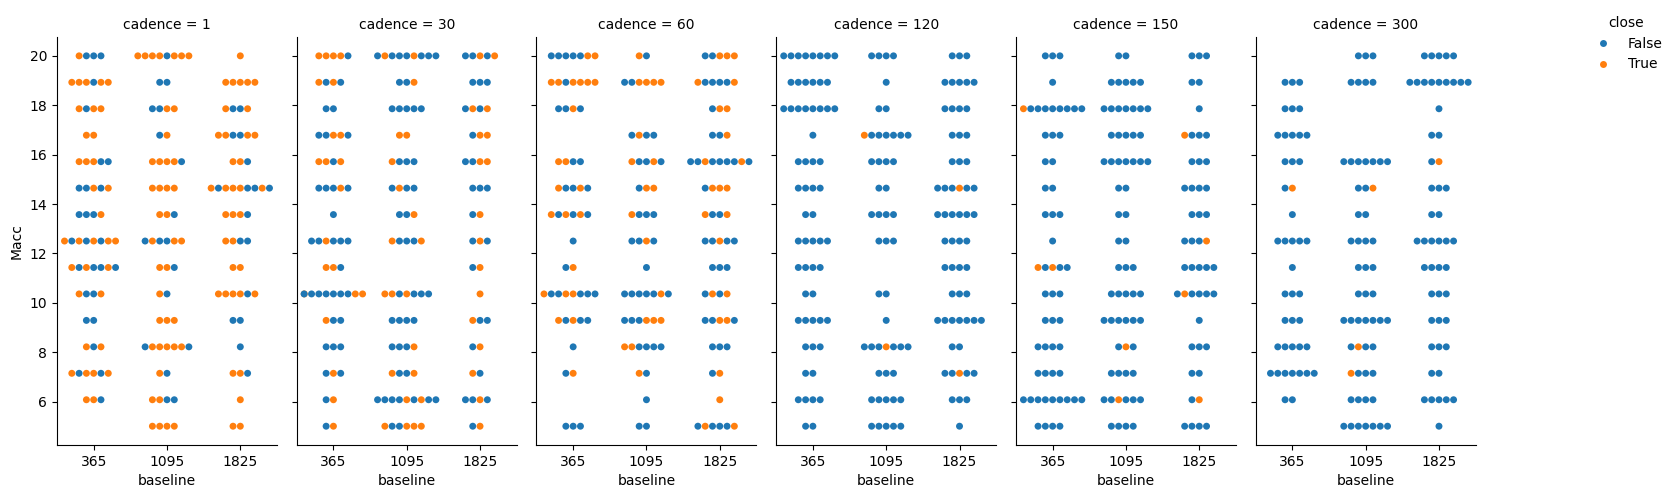

In [23]:
# a = seaborn.swarmplot(data=results, x='baseline', y='Porb', hue='close', col='cadence')
a = seaborn.catplot(
    data=results, kind="swarm",
    x='baseline', y='Macc', hue='close', col='cadence',
    aspect=.5
)
seaborn.move_legend(a, "upper left", bbox_to_anchor=(1, 1))

/Users/adam/.local/share/virtualenvs/src-VJqicAka/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 7.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/Users/adam/.local/share/virtualenvs/src-VJqicAka/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 7.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


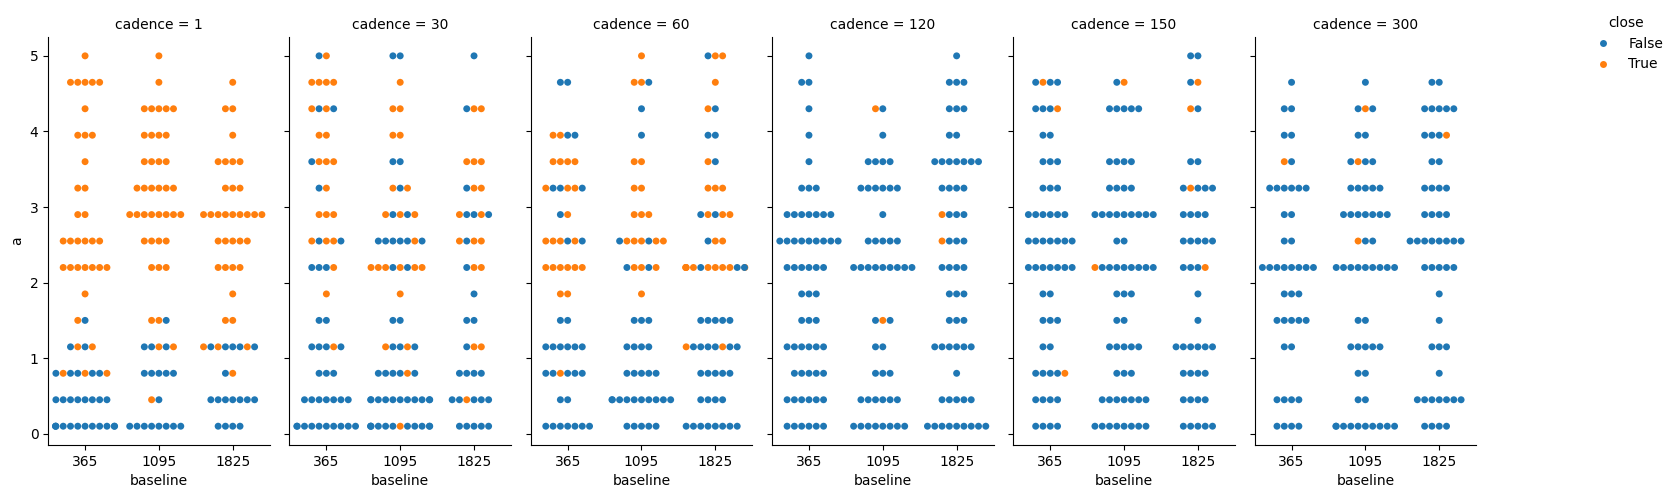

In [24]:
# a = seaborn.swarmplot(data=results, x='baseline', y='Porb', hue='close', col='cadence')
a = seaborn.catplot(
    data=results, kind="swarm",
    x='baseline', y='a', hue='close', col='cadence',
    aspect=.5
)
seaborn.move_legend(a, "upper left", bbox_to_anchor=(1, 1))